# 05: PD Model Training

This notebook trains six classification models for Probability of Default (PD) estimation on the development sample (matured loans, whose default outcome is fully observed), then scores every loan in the portfolio. Each model is tuned via RandomizedSearchCV on a stratified sample of 300,000 observations. The model with the best **cross-validated** AUC is selected, calibrated with isotonic regression on a dedicated calibration split, and only then evaluated on the held-out test set.

The development sample is split three ways so that no step reuses data it was fitted on:

| Split | Share | Used for |
|---|---|---|
| Train | 70% | hyperparameter search and model fitting |
| Calibration | 10% | fitting the isotonic calibrator |
| Test | 20% | final, untouched evaluation of ranking and calibration |

**Input:** `data/processed/checkpoint_df_PD_training.pkl`, `data/processed/features_PD_num_for_training.pkl`, `data/processed/features_PD_cat_for_training.pkl`  
**Output:** `models/<best_model>_PD.pkl`, `models/PD_model_comparison.csv`, `models/calibrated_model_PD.pkl`, `data/processed/checkpoint_df_master_with_PD.pkl`

## Libraries

In [1]:
# Run from the repository root so that data/, models/ and src/ resolve the same way
# whether the notebook is opened from the root or from production_notebooks/.
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "production_notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import shap
import os

from sklearn.model_selection     import train_test_split
from sklearn.calibration         import CalibratedClassifierCV, calibration_curve
from sklearn.frozen              import FrozenEstimator
from sklearn.metrics             import roc_auc_score, average_precision_score, brier_score_loss

from train_models_PD  import train_all_models_PD
from preprocess       import preprocess_features, apply_preprocessing
from readme_figures   import (plot_pd_model_comparison, plot_calibration_curves, plot_shap_comparison,
                              display_name)
from explain          import shap_values_for, feature_level_shap

## 1. Load Checkpoint

In [3]:
with open("data/processed/checkpoint_df_PD_training.pkl", "rb") as f:
    data = pickle.load(f)
df_PD_clean = data["df_PD_clean"]          # treated features for every loan

with open("data/processed/features_PD_num_for_training.pkl", "rb") as f:
    num_features_PD = pickle.load(f)

with open("data/processed/features_PD_cat_for_training.pkl", "rb") as f:
    cat_features_PD = pickle.load(f)

features_PD = num_features_PD + cat_features_PD

# Development sample: matured loans only
dev_PD = df_PD_clean[df_PD_clean["is_matured"] == 1]

print(f"Portfolio: {len(df_PD_clean):,} loans | development sample: {len(dev_PD):,} "
      f"(default rate {dev_PD['Target_Variable_Default'].mean():.4f})")
print(f"Features: {features_PD}")

Portfolio: 2,139,643 loans | development sample: 676,113 (default rate 0.1488)
Features: ['annual_income', 'num_open_credit_lines', 'dept_paym_income_ratio', 'monthly_payment', 'num_inq_in_12mths', 'total_credit_revolving_bal', 'used_credit_share', 'grade', 'home_ownership_status', 'emp_title']


## 2. Train / Calibration / Test Split

Stratified splits of the development sample, preserving the class distribution. The test set (20%) is set aside first; the calibration set (10% of the total) is then carved out of the remainder. All models are trained on the same training split.

In [4]:
X = dev_PD[features_PD]
y = dev_PD["Target_Variable_Default"]

# Test set first (20%), then a calibration set (10% of the total) from the rest
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_cal, y_train, y_cal = train_test_split(
    X_rest, y_rest, test_size=0.125, random_state=42, stratify=y_rest
)
del X_rest, y_rest

for name, ys in [("train", y_train), ("calibration", y_cal), ("test", y_test)]:
    print(f"{name:<12}: {len(ys):>9,} rows | default rate {ys.mean():.4f}")

train       :   473,278 rows | default rate 0.1488
calibration :    67,612 rows | default rate 0.1488
test        :   135,223 rows | default rate 0.1488


## 3. Preprocessing

RobustScaler fitted on the training split only and applied unchanged to the calibration and test splits. One-Hot Encoding applied to categorical features, with the calibration and test columns aligned to the training schema. Applied uniformly across all models as a portfolio simplification.

In [5]:
X_train, X_cal, scaler_PD = preprocess_features(
    X_train, X_cal, cat_features_PD, num_features_PD
)
X_test = apply_preprocessing(X_test, cat_features_PD, num_features_PD, X_train.columns, scaler_PD)

print(f"X_train: {X_train.shape} | X_cal: {X_cal.shape} | X_test: {X_test.shape}")

X_train: (473278, 57) | X_cal: (67612, 57) | X_test: (135223, 57)


## 4. Model Training

Six classification models are trained:
- Logistic Regression (interpretable baseline)
- Decision Tree
- Random Forest
- XGBoost
- LightGBM
- CatBoost

All models are tuned via RandomizedSearchCV (300k stratified sample, 5-fold CV, optimizing AUC-ROC). Results are saved to `models/`.

Every model gets 100 search iterations except the Random Forest, which gets 20. Its search is by far the most expensive step of the pipeline (close to 10 hours of the ~12.5 hours this notebook took with 100 iterations), and it does not change the outcome: the Random Forest is the weakest of the ensembles here (CV AUC 0.673 against 0.681 to 0.683 for the boosting models and the logistic regression), a gap that more tuning is unlikely to close. With random search, the best of 20 draws lands in the top 10% of the search space with probability 1 - 0.9^20 = 0.88, which is enough for a comparison model.

In [6]:
results_PD = train_all_models_PD(
    X_train, y_train,
    X_test,  y_test,
    sample_size=300_000,
    n_iter_overrides={"random_forest": 20},   # see the note above
)


────────────────────────────────────────────────────────────
  Training: logistic_regression_PD
────────────────────────────────────────────────────────────
  Sampling 300,000 rows for hyperparameter search...


  Running RandomizedSearchCV (100 iterations, 5-fold CV)...


  Best params : {'C': np.float64(9.83523140894843), 'class_weight': 'balanced', 'max_iter': 1000, 'penalty': 'l1', 'solver': 'saga'}
  Best CV AUC : 0.6830
  Refitting on full training set (473,278 rows)...


  Test AUC: 0.6831 | Accuracy: 0.6064 | Precision: 0.224 | Recall: 0.6676 | F1: 0.3354
  Saved: models\logistic_regression_PD.pkl | models\logistic_regression_PD_metrics.json

────────────────────────────────────────────────────────────
  Training: decision_tree_PD
────────────────────────────────────────────────────────────
  Sampling 300,000 rows for hyperparameter search...
  Running RandomizedSearchCV (100 iterations, 5-fold CV)...


  Best params : {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 14, 'min_samples_leaf': 198, 'min_samples_split': 112}
  Best CV AUC : 0.6473
  Refitting on full training set (473,278 rows)...


...

  Best params : {'colsample_bytree': np.float64(0.606182646611547), 'learning_rate': np.float64(0.1956637125175451), 'max_depth': 3, 'min_child_samples': 65, 'n_estimators': 280, 'num_leaves': 79, 'reg_alpha': np.float64(0.8530094554673601), 'reg_lambda': np.float64(0.5888977841391714), 'subsample': np.float64(0.7540390914407701)}
  Best CV AUC : 0.6814
  Refitting on full training set (473,278 rows)...


  Test AUC: 0.6829 | Accuracy: 0.6197 | Precision: 0.2284 | Recall: 0.6546 | F1: 0.3387
  Saved: models\lightgbm_PD.pkl | models\lightgbm_PD_metrics.json

────────────────────────────────────────────────────────────
  Training: catboost_PD
────────────────────────────────────────────────────────────
  Sampling 300,000 rows for hyperparameter search...


  Running RandomizedSearchCV (100 iterations, 5-fold CV)...


  Best params : {'border_count': 107, 'depth': 3, 'iterations': 383, 'l2_leaf_reg': np.float64(10.50061967050805), 'learning_rate': np.float64(0.20012142938751123), 'subsample': np.float64(0.8293751552493145)}
  Best CV AUC : 0.6821
  Refitting on full training set (473,278 rows)...


  Test AUC: 0.6837 | Accuracy: 0.6186 | Precision: 0.228 | Recall: 0.6551 | F1: 0.3382
  Saved: models\catboost_PD.pkl | models\catboost_PD_metrics.json

 Results saved to models\PD_model_comparison.csv

════════════════════════════════════════════════════════════
                        auc  accuracy  precision  recall      f1  pr_auc  cv_auc  n_iter
model                                                                                   
logistic_regression  0.6831    0.6064     0.2240  0.6676  0.3354  0.2615  0.6830     100
catboost             0.6837    0.6186     0.2280  0.6551  0.3382  0.2659  0.6821     100
lightgbm             0.6829    0.6197     0.2284  0.6546  0.3387  0.2647  0.6814     100
xgboost              0.6834    0.6224     0.2293  0.6516  0.3393  0.2647  0.6814     100
random_forest        0.6734    0.5990     0.2205  0.6688  0.3316  0.2513  0.6732      20
decision_tree        0.6507    0.5574     0.2048  0.6851  0.3153  0.2250  0.6473     100
═══════════════════════

In [7]:
# Results summary, ranked by cross-validated AUC (the selection criterion).
# Test metrics are shown for reference only; they play no role in the choice.
results_PD

,auc,accuracy,precision,recall,f1,pr_auc,cv_auc,n_iter
model,,,,,,,,
logistic_regression,0.6831,0.6064,0.2240,0.6676,0.3354,0.2615,0.6830,100
catboost,0.6837,0.6186,0.2280,0.6551,0.3382,0.2659,0.6821,100
lightgbm,0.6829,0.6197,0.2284,0.6546,0.3387,0.2647,0.6814,100
xgboost,0.6834,0.6224,0.2293,0.6516,0.3393,0.2647,0.6814,100
random_forest,0.6734,0.5990,0.2205,0.6688,0.3316,0.2513,0.6732,20
decision_tree,0.6507,0.5574,0.2048,0.6851,0.3153,0.2250,0.6473,100


Saved assets\pd_model_comparison.png


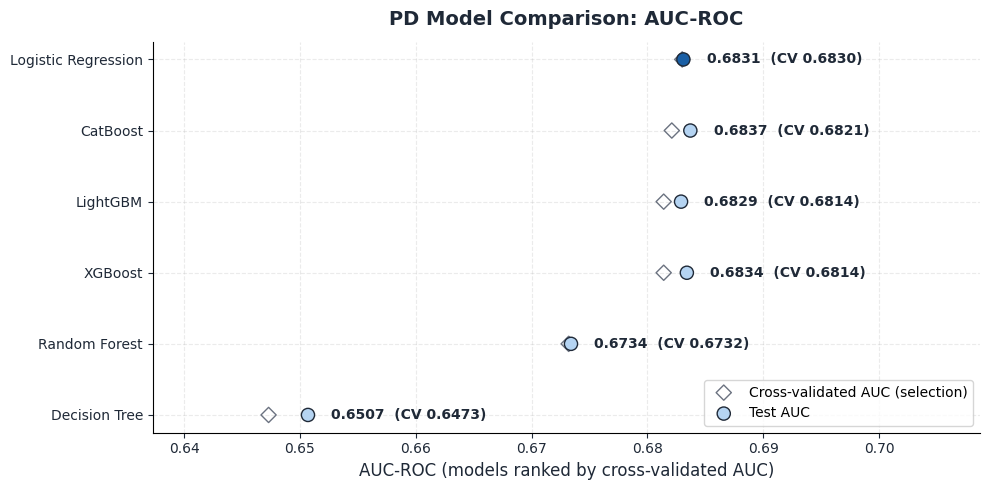

In [8]:
# Model comparison chart for the README (selected model highlighted)
plot_pd_model_comparison(results_PD, selected=results_PD["cv_auc"].idxmax())
plt.show()

## 5. Probability Calibration

The models are trained with class weighting (`class_weight='balanced'` / `scale_pos_weight`) to learn the minority class, which pushes the raw `predict_proba` outputs well above the observed default rate. Those outputs rank borrowers correctly but cannot be used as probabilities in `EL = PD x LGD x EAD`.

Isotonic regression maps the raw scores to probabilities. Two details matter:

- The calibrator is fitted on the **calibration split**, which the model has never seen. The trained model is wrapped in `FrozenEstimator`, so calibration does not refit it.
- Calibration quality is then measured on the **test split**, which neither the model nor the calibrator has seen. A calibrator evaluated on its own fitting data matches the observed default rate by construction, so that comparison would prove nothing.

In [9]:
# Load the model with the best cross-validated AUC
best_name = results_PD["cv_auc"].idxmax()
with open(f"models/{best_name}_PD.pkl", "rb") as f:
    model_PD = pickle.load(f)
print(f"Selected model: {best_name} (CV AUC {results_PD.loc[best_name, 'cv_auc']})")

# Raw probabilities on the untouched test split
y_prob_test_raw = model_PD.predict_proba(X_test)[:, 1]
print(f"Mean PD raw (test): {y_prob_test_raw.mean():.4f} | default rate (test): {y_test.mean():.4f}")

Selected model: logistic_regression (CV AUC 0.683)
Mean PD raw (test): 0.4636 | default rate (test): 0.1488


In [10]:
# Fit the isotonic calibrator on the calibration split; FrozenEstimator keeps the
# trained model as it is (no refitting on the calibration data).
calibrated_model_PD = CalibratedClassifierCV(FrozenEstimator(model_PD), method="isotonic")
calibrated_model_PD.fit(X_cal, y_cal)

# Evaluate on the test split, unseen by both the model and the calibrator
y_prob_test_cal = calibrated_model_PD.predict_proba(X_test)[:, 1]
print(f"Mean PD calibrated (test): {y_prob_test_cal.mean():.4f} | default rate (test): {y_test.mean():.4f}")
print(f"Brier score raw: {brier_score_loss(y_test, y_prob_test_raw):.4f} | "
      f"calibrated: {brier_score_loss(y_test, y_prob_test_cal):.4f}")
print(f"AUC raw: {roc_auc_score(y_test, y_prob_test_raw):.4f} | "
      f"calibrated: {roc_auc_score(y_test, y_prob_test_cal):.4f}")

Mean PD calibrated (test): 0.1485 | default rate (test): 0.1488
Brier score raw: 0.2263 | calibrated: 0.1199
AUC raw: 0.6831 | calibrated: 0.6827


Saved assets\calibration_curve.png


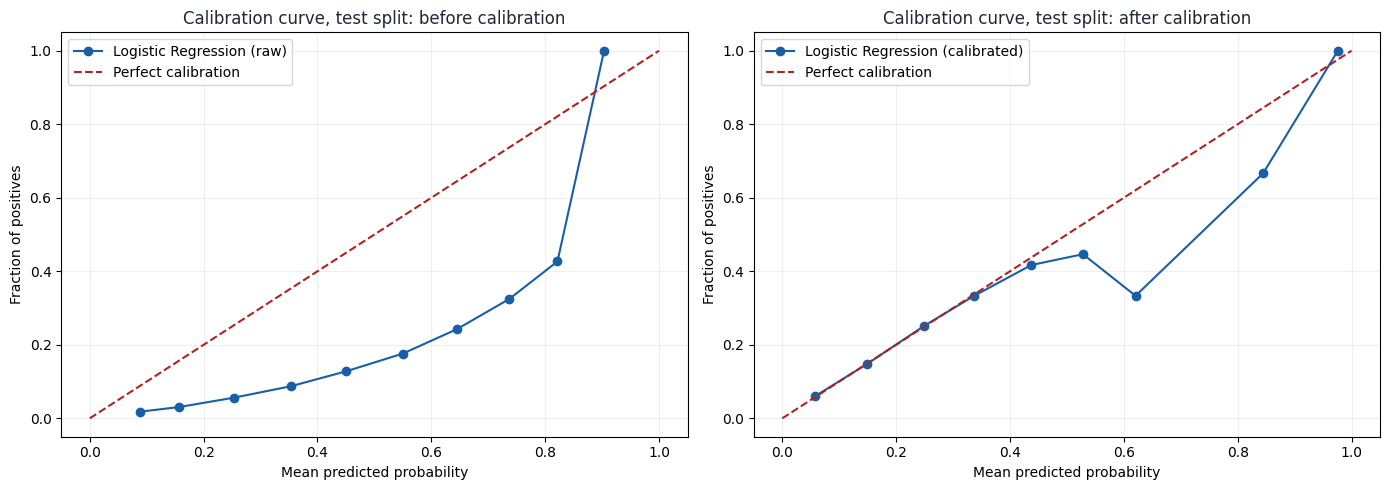

In [11]:
# Calibration curves on the test split, before and after (also saved for the README)
plot_calibration_curves(y_prob_test_raw, y_prob_test_cal, y_test, display_name(best_name))
plt.show()

In [12]:
# Save calibrated model
with open("models/calibrated_model_PD.pkl", "wb") as f:
    pickle.dump(calibrated_model_PD, f)

print("Calibrated model saved.")

Calibrated model saved.


## 6. SHAP Analysis

SHAP values split each prediction into one additive contribution per feature, measured from the average prediction of a background sample. The summary plot shows, for 50,000 test loans, how each encoded column pushes the default score up or down (in log-odds) and how that depends on the feature's value.

SHAP values shape: (50000, 57)


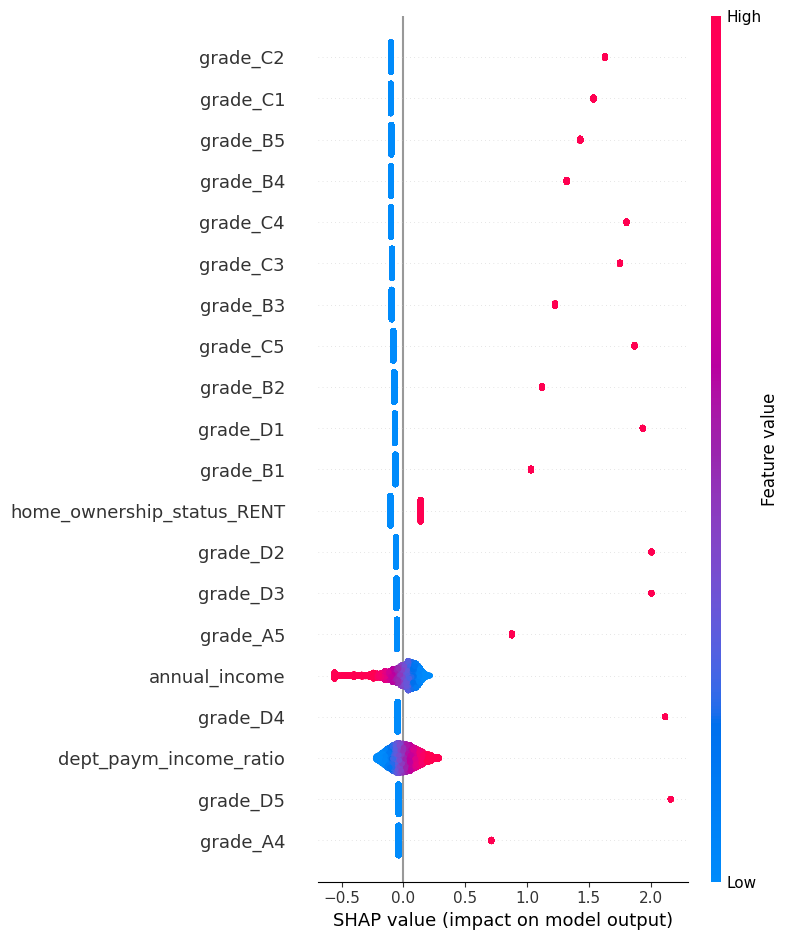

In [13]:
# SHAP on a representative sample of the test split. The explainer follows the
# selected model: LinearExplainer for a linear model (values in log-odds),
# TreeExplainer for a tree ensemble.
X_shap = X_test.sample(n=50_000, random_state=42).astype(float)
shap_values = shap_values_for(model_PD, X_shap, X_train)

print(f"SHAP values shape: {shap_values.shape}")

shap.summary_plot(shap_values, X_shap, max_display=20, show=False)
plt.savefig("assets/shap_pd_final.png", dpi=150, bbox_inches="tight")
plt.show()

### The same explanation from a second model family

The selection picks the best cross-validated AUC, but the top models are within a few thousandths of each other, so the explanation should not hinge on that choice. The cell below explains the same 50,000 test loans with the best model of the other family: the strongest tree ensemble if a linear model was selected, the logistic regression otherwise. For a linear model SHAP values reduce to coefficient × (feature − background mean); for trees, TreeExplainer computes them exactly. Both are in log-odds.

One-hot columns are summed back into their original feature before taking the mean absolute value (SHAP values are additive), so each bar is one variable as it exists in the data. Agreement between the two families means the drivers are a property of the data, not of one model.

                            Logistic Regression  CatBoost
grade                                      42.0      28.9
home_ownership_status                       9.8       8.6
annual_income                               8.3      11.4
emp_title                                   7.7       6.1
dept_paym_income_ratio                      7.5       7.4
monthly_payment                             6.3       8.1
num_open_credit_lines                       6.1       7.1
num_inq_in_12mths                           5.5       7.3
total_credit_revolving_bal                  4.4       7.4
used_credit_share                           2.4       7.8

Spearman rank correlation between the two rankings: 0.54
Saved assets\shap_pd_comparison.png


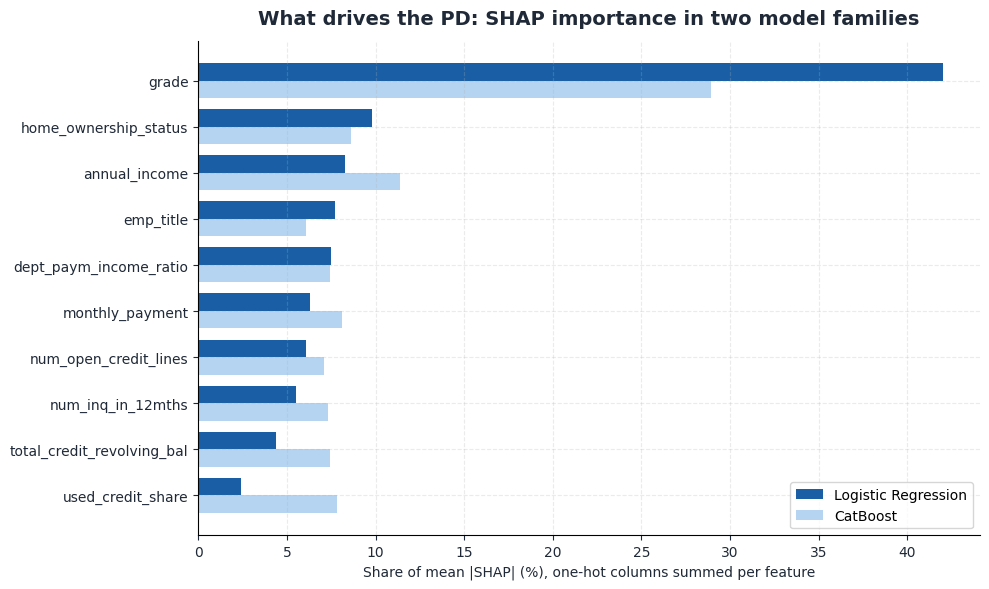

In [14]:
# Best model of the other family, explained on the same sample
LINEAR_MODELS = {"logistic_regression"}
ranked = results_PD.sort_values("cv_auc", ascending=False).index
other_name = next(m for m in ranked
                  if (m in LINEAR_MODELS) != (best_name in LINEAR_MODELS) and m != "decision_tree")
with open(f"models/{other_name}_PD.pkl", "rb") as f:
    model_other_PD = pickle.load(f)
shap_values_other = shap_values_for(model_other_PD, X_shap, X_train)

# Feature-level importance (one-hot columns summed), as a share of the total
importance_PD = pd.DataFrame({
    display_name(name): feature_level_shap(values, X_shap.columns, features_PD, cat_features_PD)
    for name, values in [(best_name, shap_values), (other_name, shap_values_other)]
})
importance_share_PD = (100 * importance_PD / importance_PD.sum()).round(1)
print(importance_share_PD.sort_values(importance_share_PD.columns[0], ascending=False))
print(f"\nSpearman rank correlation between the two rankings: "
      f"{importance_PD.corr(method='spearman').iloc[0, 1]:.2f}")

plot_shap_comparison(importance_share_PD)
plt.show()

## 7. PD Inference on Full Portfolio

Every loan is scored, matured or not: the treated features from `03_eda_pd` go through the preprocessing fitted on the training split (same dummies, same scaler) and the calibrated model.

In [15]:
# Calibrated PD for every loan in the portfolio
X_full = apply_preprocessing(df_PD_clean[features_PD], cat_features_PD, num_features_PD,
                             X_train.columns, scaler_PD)
y_prob_PD = calibrated_model_PD.predict_proba(X_full)[:, 1]

print(f"PD computed for {len(y_prob_PD):,} loans")
print(f"Mean PD    : {y_prob_PD.mean():.4f}")
print(f"Median PD  : {np.median(y_prob_PD):.4f}")

PD computed for 2,139,643 loans
Mean PD    : 0.1608
Median PD  : 0.1502


In [16]:
# Verify PD separation between defaulted and non-defaulted populations
with open("data/processed/checkpoint_DataFrame_for_EDA.pkl", "rb") as f:
    data = pickle.load(f)
df_master_features = data["df_master_features"]

df_master_features["PD"] = pd.Series(y_prob_PD, index=X_full.index)

# Record which split each loan belongs to, so that 07_expected_loss can validate
# the Expected Loss on the test loans alone (out of sample). Loans that have not
# reached maturity were never used for fitting.
df_master_features["split_PD"] = "not_matured"
df_master_features.loc[X_train.index, "split_PD"] = "train"
df_master_features.loc[X_cal.index, "split_PD"] = "calibration"
df_master_features.loc[X_test.index, "split_PD"] = "test"
print(df_master_features["split_PD"].value_counts())

# Separation on the development sample, where the default outcome is complete
dev = df_master_features["is_matured"] == 1
print("\nPD (matured): non-defaulted:")
print(df_master_features.loc[dev & (df_master_features["Target_Variable_Default"] == 0), "PD"].describe())
print("\nPD (matured): defaulted:")
print(df_master_features.loc[dev & (df_master_features["Target_Variable_Default"] == 1), "PD"].describe())
print("\nMean PD of loans not yet matured: "
      f"{df_master_features.loc[~dev, 'PD'].mean():.4f} "
      f"(observed default rate so far {df_master_features.loc[~dev, 'Target_Variable_Default'].mean():.4f}, incomplete)")

split_PD
not_matured    1463530
train           473278
test            135223
calibration      67612
Name: count, dtype: int64

PD (matured): non-defaulted:
count    575524.000000
mean          0.140282
std           0.080916
min           0.000000
25%           0.070968
50%           0.132049
75%           0.198439
max           0.966157
Name: PD, dtype: float64

PD (matured): defaulted:
count    100589.000000
mean          0.195405
std           0.087873
min           0.000000
25%           0.132049
50%           0.198439
75%           0.250945
max           1.000000
Name: PD, dtype: float64

Mean PD of loans not yet matured: 0.1665 (observed default rate so far 0.1224, incomplete)


In [17]:
# Save df_master_features with PD column
with open("data/processed/checkpoint_df_master_with_PD.pkl", "wb") as f:
    pickle.dump({"df_master_features": df_master_features}, f)

print("Saved df_master_features with PD column.")

Saved df_master_features with PD column.
